<a href="https://colab.research.google.com/github/tevfikaytekin/recommender_systems_course/blob/main/auto_diff.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Automatic Differentiation: From Theory to PyTorch Autograd

This notebook explores the fundamental mechanics of **Automatic Differentiation (Autodiff)**, the core algorithm that powers neural network training. We will break down the mathematical foundations of derivatives and the Chain Rule, manually construct and evaluate a computational graph, and analyze the theoretical differences between forward-mode and backward-mode (backpropagation) differentiation. Finally, we will connect these manual calculations to **PyTorch**, demonstrating how its `autograd` engine automatically builds graphs and computes gradients behind the scenes.

### Derivatives and Partial Derivatives

*Note: The following section serves as a brief refresher on the core concepts of derivatives and partial derivatives, providing the essential mathematical background for the automatic differentiation algorithms discussed later.*

**1. Derivative**

A **derivative** measures the rate of change of a function with respect to a single input variable. Geometrically, it represents the slope of the tangent line to the function's curve at a given point.
*   **Example:** Let $f(x) = x^2$.
*   The derivative of $f$ with respect to $x$ is denoted as $f'(x)$ or $\frac{df}{dx}$.
*   Using basic calculus power rules, $\frac{df}{dx} = 2x$.
*   At $x = 4$, the rate of change is $2(4) = 8$. This means for a tiny increase in $x$ around $4$, $f(x)$ will increase 8 times as fast. For example, if we increase $x$ by $0.1$ (from $4$ to $4.1$), the new value is $f(4.1) = 4.1^2 = 16.81$. The increase in $f(x)$ is $16.81 - 4^2 = 16.81 - 16 = 0.81$, which is closely approximated by our derivative prediction: $8 \times 0.1 = 0.8$.

**2. Partial Derivative**

In deep learning, our functions (like the loss function) almost always depend on *multiple* variables (often millions of weights and biases). A **partial derivative** measures the rate of change of a multi-variable function with respect to *one* specific variable, while treating all other variables as constants.
*   **Example:** Let $f(x, y) = x^2 + 3y^4$.
*   The partial derivative of $f$ with respect to $x$ (treating $y$ as a constant) is denoted as $\frac{\partial f}{\partial x}$. Since $3y^4$ acts like a constant, its derivative is $0$. Thus, $\frac{\partial f}{\partial x} = 2x + 0 = 2x$. At $x = 4$ and $y = 2$, this rate of change is $2(4) = 8$. This means for a tiny increase in $x$ around $4$ (while keeping $y$ constant), $f(x, y)$ will increase 8 times as fast.
*   The partial derivative of $f$ with respect to $y$ (treating $x$ as a constant) is $\frac{\partial f}{\partial y}$. Here, $x^2$ acts as a constant, so $\frac{\partial f}{\partial y} = 0 + 3(4y^3) = 12y^3$. At $x = 5$ and $y = 2$, this rate of change is $12(2^3) = 96$. This means for a tiny increase in $y$ around $2$ (while keeping $x$ constant), $f(x, y)$ will increase 96 times as fast.

A **gradient** is simply a vector (a list) containing all the partial derivatives of a function.

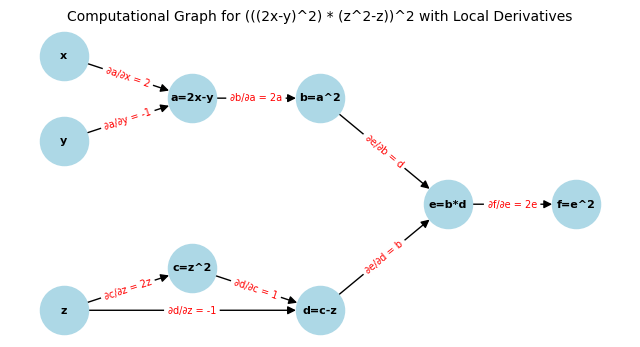

In [ ]:
# @title Computational Graphs { display-mode: "form" }
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

nodes = ['x', 'y', 'z', 'a=2x-y', 'b=a^2', 'c=z^2', 'd=c-z', 'e=b*d', 'f=e^2']
G.add_nodes_from(nodes)

edges_with_labels = [
    ('x', 'a=2x-y', '∂a/∂x = 2'),
    ('y', 'a=2x-y', '∂a/∂y = -1'),
    ('a=2x-y', 'b=a^2', '∂b/∂a = 2a'),
    ('z', 'c=z^2', '∂c/∂z = 2z'),
    ('c=z^2', 'd=c-z', '∂d/∂c = 1'),
    ('z', 'd=c-z', '∂d/∂z = -1'),
    ('b=a^2', 'e=b*d', '∂e/∂b = d'),
    ('d=c-z', 'e=b*d', '∂e/∂d = b'),
    ('e=b*d', 'f=e^2', '∂f/∂e = 2e')
]

for u, v, label in edges_with_labels:
    G.add_edge(u, v, label=label)

pos = {
    'x': (0, 2),
    'y': (0, 1),
    'z': (0, -1),
    'a=2x-y': (1, 1.5),
    'c=z^2': (1, -0.5),
    'b=a^2': (2, 1.5),
    'd=c-z': (2, -1),
    'e=b*d': (3, 0.25),
    'f=e^2': (4, 0.25)
}

plt.figure(figsize=(8.0, 4.0))

nx.draw_networkx_nodes(G, pos, node_size=1200, node_color='lightblue')

nx.draw_networkx_edges(G, pos, arrowsize=12, node_size=1200, arrows=True)

nx.draw_networkx_labels(G, pos, font_size=8.0, font_weight='bold')

edge_labels = nx.get_edge_attributes(G, 'label')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color='red', font_size=7.0)

plt.title("Computational Graph for (((2x-y)^2) * (z^2-z))^2 with Local Derivatives", fontsize=10.0)
plt.axis("off")
plt.show()

This computational graph represents the function $f(x, y, z) = (((2x-y)^2)(z^2-z))^2$ by breaking it down into a sequence of elementary operations. Each node acts as an intermediate variable, and the directed edges map the flow of computation. The labels on the edges represent the **local partial derivatives**—how much the target node changes for a tiny change in the source node.

To find the overall partial derivatives of the final output $f$ with respect to the inputs $x, y,$ and $z$, we use the **Chain Rule**. In the context of the graph, this means **multiplying the local derivatives along the paths** from the input to the output. If there are multiple paths from an input to the output (like for $z$), we **sum** the products of those paths.

*   **Path for $x$:** $x \rightarrow a \rightarrow b \rightarrow e \rightarrow f$
    *   $\frac{\partial f}{\partial x} = \frac{\partial f}{\partial e} \cdot \frac{\partial e}{\partial b} \cdot \frac{\partial b}{\partial a} \cdot \frac{\partial a}{\partial x}$
*   **Path for $y$:** $y \rightarrow a \rightarrow b \rightarrow e \rightarrow f$
    *   $\frac{\partial f}{\partial y} = \frac{\partial f}{\partial e} \cdot \frac{\partial e}{\partial b} \cdot \frac{\partial b}{\partial a} \cdot \frac{\partial a}{\partial y}$
*   **Paths for $z$:** There are two paths: $z \rightarrow c \rightarrow d \rightarrow e \rightarrow f$ and $z \rightarrow d \rightarrow e \rightarrow f$
    *   $\frac{\partial f}{\partial z} = \left( \frac{\partial f}{\partial e} \cdot \frac{\partial e}{\partial d} \cdot \frac{\partial d}{\partial c} \cdot \frac{\partial c}{\partial z} \right) + \left( \frac{\partial f}{\partial e} \cdot \frac{\partial e}{\partial d} \cdot \frac{\partial d}{\partial z} \right)$

In [ ]:
# Let's choose a set of POSITIVE values to evaluate the derivatives
x, y, z = 1.1, 1.2, 1.5

print(f"Evaluating at x={x}, y={y}, z={z}\n")

# 1. FORWARD PASS (Compute intermediate variables)
a = 2 * x - y
b = a**2
c = z**2
d = c - z
e = b * d
f = e**2

print(f"--- Forward Pass ---")
print(f"a = {a:.1f}, b = {b:.1f}, c = {c:.1f}, d = {d:.1f}, e = {e:.1f}, f = {f:.1f}\n")

# 2. LOCAL DERIVATIVES
da_dx = 2.0  # Derivative of (2x-y) wrt x is 2
da_dy = -1.0 # Derivative of (2x-y) wrt y is -1
db_da = 2 * a
dc_dz = 2 * z
dd_dc = 1.0
dd_dz = -1.0
de_db = d
de_dd = b
df_de = 2 * e

print(f"--- Local Derivatives ---")
print(f"∂a/∂x={da_dx:.1f}, ∂a/∂y={da_dy:.1f}, ∂b/∂a={db_da:.1f}, ∂c/∂z={dc_dz:.1f}, ∂d/∂c={dd_dc:.1f}, ∂d/∂z={dd_dz:.1f}, ∂e/∂b={de_db:.1f}, ∂e/∂d={de_dd:.1f}, ∂f/∂e={df_de:.1f}\n")

# 3. CHAIN RULE (Multiplying along the paths)
# For x
df_dx_chain = df_de * de_db * db_da * da_dx

# For y
df_dy_chain = df_de * de_db * db_da * da_dy

# For z (sum of two paths)
path1_z = df_de * de_dd * dd_dc * dc_dz
path2_z = df_de * de_dd * dd_dz
df_dz_chain = path1_z + path2_z

print(f"--- Chain Rule (Path Multiplications) ---")
print(f"∂f/∂x = {df_de:.1f} * {de_db:.1f} * {db_da:.1f} * {da_dx:.1f} = {df_dx_chain:.1f}")
print(f"∂f/∂y = {df_de:.1f} * {de_db:.1f} * {db_da:.1f} * {da_dy:.1f} = {df_dy_chain:.1f}")
print(f"∂f/∂z = ({df_de:.1f} * {de_dd:.1f} * {dd_dc:.1f} * {dc_dz:.1f}) + ({df_de:.1f} * {de_dd:.1f} * {dd_dz:.1f}) = {df_dz_chain:.1f}\n")

# 4. VERIFICATION WITH ANALYTICAL DERIVATIVES
# Original function: f = (((2x-y)^2) * (z^2-z))^2
# Analytical ∂f/∂x = 8 * (2x-y)^3 * (z^2-z)^2
df_dx_analytical = 8 * (2*x-y)**3 * (z**2 - z)**2

# Analytical ∂f/∂y = -4 * (2x-y)^3 * (z^2-z)^2
df_dy_analytical = -4 * (2*x-y)**3 * (z**2 - z)**2

# Analytical ∂f/∂z = 2 * (((2x-y)^2)*(z^2-z)) * (2x-y)^2 * (2z-1) = 2 * (2x-y)^4 * (z^2-z) * (2z-1)
df_dz_analytical = 2 * (2*x-y)**4 * (z**2 - z) * (2*z - 1)

print(f"--- Analytical Verification ---")
print(f"Analytical ∂f/∂x = {df_dx_analytical:.1f} | Matches Chain Rule? {round(df_dx_chain, 1) == round(df_dx_analytical, 1)}")
print(f"Analytical ∂f/∂y = {df_dy_analytical:.1f} | Matches Chain Rule? {round(df_dy_chain, 1) == round(df_dy_analytical, 1)}")
print(f"Analytical ∂f/∂z = {df_dz_analytical:.1f} | Matches Chain Rule? {round(df_dz_chain, 1) == round(df_dz_analytical, 1)}")


Evaluating at x=1.1, y=1.2, z=1.5

--- Forward Pass ---
a = 1.0, b = 1.0, c = 2.2, d = 0.8, e = 0.8, f = 0.6

--- Local Derivatives ---
∂a/∂x=2.0, ∂a/∂y=-1.0, ∂b/∂a=2.0, ∂c/∂z=3.0, ∂d/∂c=1.0, ∂d/∂z=-1.0, ∂e/∂b=0.8, ∂e/∂d=1.0, ∂f/∂e=1.5

--- Chain Rule (Path Multiplications) ---
∂f/∂x = 1.5 * 0.8 * 2.0 * 2.0 = 4.5
∂f/∂y = 1.5 * 0.8 * 2.0 * -1.0 = -2.3
∂f/∂z = (1.5 * 1.0 * 1.0 * 3.0) + (1.5 * 1.0 * -1.0) = 3.0

--- Analytical Verification ---
Analytical ∂f/∂x = 4.5 | Matches Chain Rule? True
Analytical ∂f/∂y = -2.3 | Matches Chain Rule? True
Analytical ∂f/∂z = 3.0 | Matches Chain Rule? True


### Demonstrating the meaning of Partial Derivatives

The partial derivative $\frac{\partial f}{\partial x} = 4.5$ means that a tiny increase in $x$ by $\Delta x$ will lead to an increase in $f$ by approximately $4.5 \times \Delta x$.

Similarly, $\frac{\partial f}{\partial y} = -2.3$ means that a tiny increase in $y$ by $\Delta y$ will lead to a decrease in $f$ by approximately $-2.3 \times \Delta y$.

In [ ]:
# Original values
x, y, z = 1.1, 1.2, 1.5
f_orig = (((2*x - y)**2) * (z**2 - z))**2
print(f"Original f(x={x}, y={y}, z={z}) = {f_orig:.4f}\n")

# --- Change in x ---
delta_x = 0.001
x_new = x + delta_x
f_new_x = (((2*x_new - y)**2) * (z**2 - z))**2
actual_change_x = f_new_x - f_orig
predicted_change_x = df_dx_analytical * delta_x

print(f"--- Increasing x by {delta_x} ---")
print(f"New f(x={x_new:.3f}, y={y}, z={z}) = {f_new_x:.4f}")
print(f"Actual change in f: {actual_change_x:.5f}")
print(f"Predicted change in f (df/dx * delta_x): {predicted_change_x:.5f}\n")

# --- Change in y ---
delta_y = 0.001
y_new = y + delta_y
f_new_y = (((2*x - y_new)**2) * (z**2 - z))**2
actual_change_y = f_new_y - f_orig
predicted_change_y = df_dy_analytical * delta_y

print(f"--- Increasing y by {delta_y} ---")
print(f"New f(x={x}, y={y_new:.3f}, z={z}) = {f_new_y:.4f}")
print(f"Actual change in f: {actual_change_y:.5f}")
print(f"Predicted change in f (df/dy * delta_y): {predicted_change_y:.5f}")


Original f(x=1.1, y=1.2, z=1.5) = 0.5625

--- Increasing x by 0.001 ---
New f(x=1.101, y=1.2, z=1.5) = 0.5670
Actual change in f: 0.00451
Predicted change in f (df/dx * delta_x): 0.00450

--- Increasing y by 0.001 ---
New f(x=1.1, y=1.201, z=1.5) = 0.5603
Actual change in f: -0.00225
Predicted change in f (df/dy * delta_y): -0.00225


# Forward Mode vs Backward Mode Automatic Differentiation



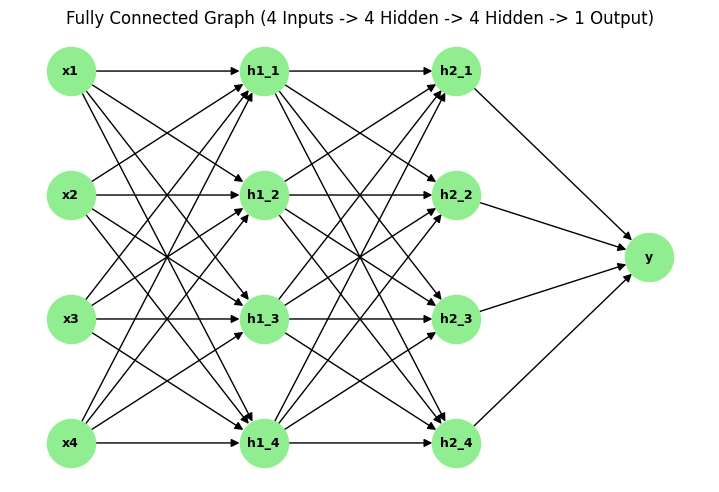

In [ ]:
# @title Fully Connected Graph Generation { display-mode: "form" }
import networkx as nx
import matplotlib.pyplot as plt

# Create a directed graph
G = nx.DiGraph()

# Define fully connected edges (4 inputs, 2 hidden layers with 4 nodes each, 1 output)
inputs = [f'x{i}' for i in range(1, 5)]
hidden1 = [f'h1_{i}' for i in range(1, 5)]
hidden2 = [f'h2_{i}' for i in range(1, 5)]

edges = [(u, v) for u in inputs for v in hidden1] + \
        [(u, v) for u in hidden1 for v in hidden2] + \
        [(v, 'y') for v in hidden2]
G.add_edges_from(edges)

# Set positions for a clear left-to-right hierarchical layout
pos = {}
for i, node in enumerate(inputs): pos[node] = (0, 4 - i)
for i, node in enumerate(hidden1): pos[node] = (1, 4 - i)
for i, node in enumerate(hidden2): pos[node] = (2, 4 - i)
pos['y'] = (3, 2.5)

plt.figure(figsize=(7, 4.5))

# Draw the graph
nx.draw(
    G, pos,
    with_labels=True,
    node_size=1200,
    node_color='lightgreen',
    font_size=9,
    font_weight='bold',
    arrows=True,
    arrowsize=12
)

plt.title("Fully Connected Graph (4 Inputs -> 4 Hidden -> 4 Hidden -> 1 Output)", fontsize=12)
plt.axis("off")
plt.show()

## A simple network illustrating the dense-dependency case

Take a fully connected network with $n$ inputs, two hidden layers of width $n$, and a scalar output:

$$x \in \mathbb{R}^n \;\to\; h_1 = \sigma(W_1 x) \;\to\; h_2 = \sigma(W_2 h_1) \;\to\; L = \sum_j h_{2,j}$$

Here $W_1$ and $W_2$ are $n \times n$, so the graph has about $2n^2$ edges ($n^2$ per dense layer, plus $n$ for the final sum).

**Reverse-mode.** One backward sweep touches each edge once, so the gradient with respect to all $n$ inputs costs about $2n^2$ edge operations.

**Forward-mode.** The tangent of a single input $x_i$ reaches all $n$ units of $h_1$ ($n$ edges). Since every unit of $h_1$ feeds every unit of $h_2$, it then spreads across all $n^2$ edges of the second layer, followed by $n$ edges into $L$. So each input costs about $n^2$ operations, and all $n$ inputs cost about $n^3$.

The ratio is

$$\frac{n^3}{2n^2} = \frac{n}{2},$$

so forward-mode is linearly worse in $n$.

**Why two dense layers are needed.** With only one dense layer ($x \to h_1 \to L$), both costs are about $n^2$, because the tangent has no later dense layer to spread through. Depth of at least two dense layers is needed to see the gap.

*Note: The above calculations assume that a forward pass has already been completed and all local derivatives (on the edges) are already calculated and stored.*

*Note: The derivation above takes the derivatives with respect to the input ($x$) rather than the network weights ($W_1, W_2$). However, the logic and the complexity gap remain entirely valid for weight gradients, as tangents from the weights must similarly propagate through the subsequent dense layers.*

### Connecting Theory to PyTorch Autograd

PyTorch automatically builds a **Dynamic Computational Graph** (also known as a Directed Acyclic Graph or DAG) under the hood as you perform operations on tensors. When you call `.backward()`, it traverses this graph in reverse (Reverse-Mode Autodiff) to compute the gradients.

First, let's install `torchviz` to visualize PyTorch's internal graphs.

In [ ]:
!pip install torchviz

Now, let's redefine our function $f(x, y, z) = (((2x-y)^2)(z^2-z))^2$ using PyTorch tensors. We must set `requires_grad=True` on our input tensors so PyTorch knows it needs to track their operations and compute their gradients.

In [ ]:
import torch

# 1. Define inputs as tensors and tell PyTorch to track gradients
# We use the same values as our manual calculation: x=1.1, y=1.2, z=1.5
x = torch.tensor([1.1], requires_grad=True)
y = torch.tensor([1.2], requires_grad=True)
z = torch.tensor([1.5], requires_grad=True)

# 2. Forward Pass (PyTorch builds the computational graph here)
a = 2 * x - y
b = a ** 2
c = z ** 2
d = c - z
e = b * d
f = e ** 2

print(f"Forward pass result: f = {f.item():.4f}\n")

# 3. Backward Pass (Reverse-Mode Autodiff)
# We pass retain_graph=True so we can visualize it in the next cell!
f.backward(retain_graph=True)

# 4. Access the computed gradients
print("--- PyTorch Computed Gradients ---")
print(f"∂f/∂x = {x.grad.item():.4f}  (Matches our manual calculation of 4.5)")
print(f"∂f/∂y = {y.grad.item():.4f}  (Matches our manual calculation of -2.3)")
print(f"∂f/∂z = {z.grad.item():.4f}  (Matches our manual calculation of 3.0)")


Forward pass result: f = 0.5625

--- PyTorch Computed Gradients ---
∂f/∂x = 4.5000  (Matches our manual calculation of 4.5)
∂f/∂y = -2.2500  (Matches our manual calculation of -2.3)
∂f/∂z = 3.0000  (Matches our manual calculation of 3.0)


### When exactly does the forward computation happen?

In the code above, the **forward computation** (or forward pass) is made exactly when you perform the mathematical operations on the tensors:

```python
# Forward pass
a = 2 * x - y
b = a ** 2
c = z ** 2
d = c - z
e = b * d

f = e ** 2
```

When standard Python executes these lines from top to bottom, PyTorch does two things simultaneously:
1. **Calculates the actual numerical values** for `a`, `b`, `c`, `d`, `e`, and `f` (this is the forward computation).
2. **Builds the dynamic computational graph** in the background, recording every operation (like multiplication, subtraction, power) so it knows how to trace it backwards later when you call `f.backward()`.

### What does `f.backward()` do?

When you call `f.backward()`, PyTorch initiates the **backward pass** (Reverse-Mode Autodiff). It takes the computational graph that was dynamically built during the forward pass and traverses it in reverse (from the output back to the inputs).

During this traversal, it:
1. Calculates the partial derivatives (gradients) using the Chain Rule.
2. Computes the gradient of `f` with respect to every leaf tensor that has `requires_grad=True` (in our case, `x`, `y`, and `z`).
3. Accumulates and stores these computed gradients in the `.grad` attribute of each respective leaf tensor (e.g., `x.grad`, `y.grad`, `z.grad`). By default, after this computation, the graph is destroyed to free up memory (unless you specify `retain_graph=True`).

Finally, we can visualize the graph that PyTorch built automatically. The blue boxes represent the input tensors, the gray boxes are the mathematical functions (like `MulBackward` for multiplication, `PowBackward` for powers), and the green box is the starting point for backpropagation.

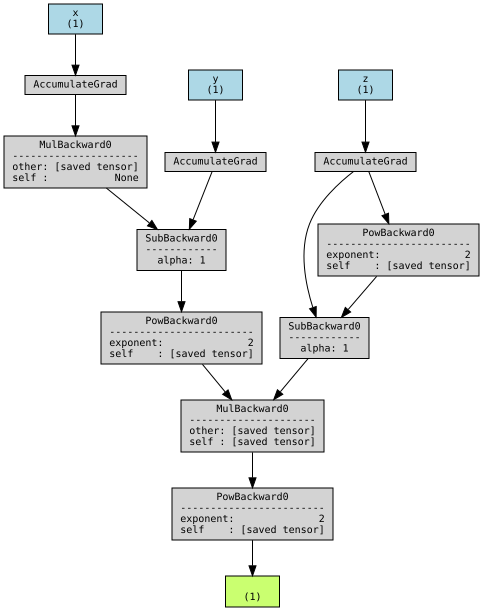

In [ ]:
import torch
from torchviz import make_dot

# Re-initialize tensors and forward pass to ensure they are available as PyTorch objects
x = torch.tensor([1.1], requires_grad=True)
y = torch.tensor([1.2], requires_grad=True)
z = torch.tensor([1.5], requires_grad=True)

a = 2 * x - y
b = a ** 2
c = z ** 2
d = c - z
e = b * d
f = e ** 2

# Visualize the computational graph
# show_attrs and show_saved show detailed properties of the backward functions
# Note: 'f' is removed from params, as params should only contain leaf tensors
dot = make_dot(f, params={'x': x, 'y': y, 'z': z}, show_attrs=True, show_saved=False)

# Make the graph size a bit larger for readability
dot.attr(size="12,12")

display(dot)


### What about intermediate variables?

You might have noticed that we only set `requires_grad=True` for `x`, `y`, and `z`. What about `a`, `b`, `c`, `d`, and `e`?

In PyTorch:
1. Tensors you create directly with `requires_grad=True` are called **leaf tensors**.
2. Tensors created as a result of operations on these leaf tensors are **non-leaf tensors** (intermediate nodes). PyTorch automatically knows they are part of the graph and tracks their operations.
3. By default, to save memory, PyTorch **discards the gradients** of non-leaf tensors after `.backward()` is called.

If you want to inspect the gradient of an intermediate variable (for example, $\frac{\partial f}{\partial e}$), you must call `.retain_grad()` on that tensor before calling `.backward()`.

In [ ]:
import torch
import warnings

# Re-initialize inputs
x = torch.tensor([1.1], requires_grad=True)
y = torch.tensor([1.2], requires_grad=True)
z = torch.tensor([1.5], requires_grad=True)

# Forward pass
a = 2 * x - y
b = a ** 2
c = z ** 2
d = c - z
e = b * d

# Tell PyTorch to keep the gradient for the intermediate variable 'e'
e.retain_grad()

f = e ** 2

# Backward pass
f.backward()

print(f"Gradient of f with respect to e (∂f/∂e): {e.grad.item():.4f}")

# Let's check what happens if we try to access the gradient of 'b' (which we didn't retain)
# We use warnings.catch_warnings() to suppress the expected PyTorch warning for a cleaner output
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    print(f"Gradient of f with respect to b (∂f/∂b): {b.grad}")

Gradient of f with respect to e (∂f/∂e): 1.5000
Gradient of f with respect to b (∂f/∂b): None


### From Autograd to Neural Networks

How does this all connect to Neural Networks? Let's map the concepts we just explored to the standard PyTorch neural network training process:

1.  **Inputs ($x, y, z$) $\rightarrow$ Model Parameters (Weights and Biases):** In a neural network, the values we want to update are the weights and biases. These are created as leaf tensors with `requires_grad=True`.
2.  **Output ($f$) $\rightarrow$ Loss Function:** The final output of our computational graph is the **Loss**. It measures how far off our network's predictions are from the true targets.
3.  **Forward Pass:** Data flows through the network layers (the intermediate operations) to compute the prediction, and then the loss is calculated.
4.  **Backward Pass (`loss.backward()`):** PyTorch traverses the dynamic computational graph backward to calculate the gradients of the loss with respect to every single weight and bias in the network.
5.  **Updating Parameters (Optimizer):** An optimizer (like SGD or Adam) takes these gradients and slightly adjusts the weights and biases to reduce the loss in the next forward pass (e.g., $weight = weight - learning\_rate \times gradient$).

Let's see this in action with a simple 1-layer neural network (Linear Regression) trained to learn the function $y = 3x + 2$.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# 1. Create a toy dataset: y = 3x + 2 + noise
torch.manual_seed(42)
X = torch.randn(100, 1) * 10
Y = 3 * X + 2 + torch.randn(100, 1) * 2 # Add some noise

# 2. Define a simple Neural Network Model
# nn.Linear automatically creates weight and bias tensors with requires_grad=True
class SimpleNet(nn.Module):
    def __init__(self):
        super(SimpleNet, self).__init__()
        self.linear = nn.Linear(1, 1) # 1 input feature, 1 output feature

    def forward(self, x):
        return self.linear(x) # y = w*x + b

model = SimpleNet()


print("Initial Model Parameters:")
for name, param in model.named_parameters():
    print(f"{name}: value={param.item():.4f}, requires_grad={param.requires_grad}")

Initial Model Parameters:
linear.weight: value=0.4801, requires_grad=True
linear.bias: value=0.8415, requires_grad=True


Notice that the parameters inside `nn.Linear` automatically have `requires_grad=True`!

Now let us do the training.


Starting Training...
Epoch 10/150, Loss: 250.7213
Epoch 20/150, Loss: 52.4284
Epoch 30/150, Loss: 3.9841
Epoch 40/150, Loss: 7.0663
Epoch 50/150, Loss: 6.9462
Epoch 60/150, Loss: 3.7518
Epoch 70/150, Loss: 3.1567
Epoch 80/150, Loss: 3.2787
Epoch 90/150, Loss: 3.1596
Epoch 100/150, Loss: 3.1230
Epoch 110/150, Loss: 3.1289
Epoch 120/150, Loss: 3.1226
Epoch 130/150, Loss: 3.1217
Epoch 140/150, Loss: 3.1218
Epoch 150/150, Loss: 3.1215

Final Model Parameters (Should be close to weight=3.0, bias=2.0):
linear.weight: value=3.0022
linear.bias: value=2.0722


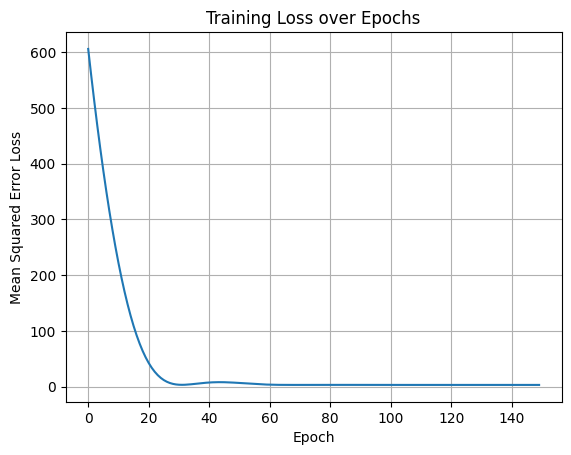

In [ ]:
# Re-initialize the model so we train from scratch every time this cell is run!
model = SimpleNet()

# Define the Loss Function and Optimizer
criterion = nn.MSELoss() # Mean Squared Error (our 'f' node from the previous examples)
# Optimizer Adam adapts the learning rate for each parameter individually!
optimizer = optim.Adam(model.parameters(), lr=0.1)

epochs = 150
losses = []

print("\nStarting Training...")
for epoch in range(epochs):
    # --- THE FORWARD PASS ---
    # 1. Pass data through the model to get predictions (builds the graph)
    predictions = model(X)

    # 2. Calculate the loss (the final node in our graph)
    loss = criterion(predictions, Y)

    # --- THE BACKWARD PASS ---
    # 3. Clear old gradients from the previous step
    # (Otherwise gradients would accumulate in param.grad)
    optimizer.zero_grad()

    # 4. Compute gradients of the loss wrt all parameters (Reverse-Mode Autodiff)
    loss.backward()

    # --- THE UPDATE ---
    # 5. Optimizer updates weights based on gradients (e.g., w = w - lr * w.grad)
    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {loss.item():.4f}")

print("\nFinal Model Parameters (Should be close to weight=3.0, bias=2.0):")
for name, param in model.named_parameters():
    print(f"{name}: value={param.item():.4f}")

# Plot the loss curve
plt.plot(losses)
plt.title("Training Loss over Epochs")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")
plt.grid(True)
plt.show()


### What just happened? Gradient Descent

The training loop above applies a fundamental optimization algorithm known as **Gradient Descent** (specifically, we used a popular variant called *Adam*).

At a high level, gradient descent works by iteratively finding the minimum of the loss function. In step 4 (`loss.backward()`), we compute the gradient (the direction of steepest ascent) of the loss with respect to each model parameter. In step 5 (`optimizer.step()`), the algorithm updates the parameters by taking a small step in the *opposite* direction of the gradient to reduce the overall loss. The size of this step is controlled by the **learning rate** parameter (`lr=0.1`). By repeating this over many epochs, the model's weights 'descend' down the error surface until they converge on a solution.

### Visualizing the Neural Network's Computational Graph

Let's use `torchviz` to see the actual graph PyTorch builds for our 1-layer neural network during a single forward pass and loss calculation.

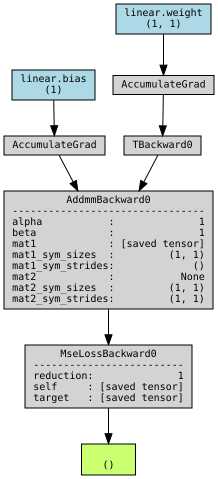

In [ ]:
# Take a single data point to trace the graph
x_sample = X[0:1]
y_sample = Y[0:1]

# Forward pass to build the graph
prediction = model(x_sample)
loss = criterion(prediction, y_sample)

# Visualize the graph
# We pass the model's parameters so they are labeled clearly as leaf nodes
params = dict(model.named_parameters())
dot = make_dot(loss, params=params, show_attrs=True, show_saved=False)

# Adjust size for better readability
dot.attr(size="10,10")
display(dot)

## Exercises

Now it's your turn to practice! Try completing the following exercises to test your understanding of PyTorch Autograd and Neural Networks.

### Exercise 1: Custom Function Autograd
Define the function $g(u, v) = \ln(u + v^2) \times u$ using PyTorch tensors.
1. Initialize tensors $u = 2.0$ and $v = 3.0$ with `requires_grad=True`.
2. Compute the forward pass for $g(u, v)$. (Hint: use `torch.log()`)
3. Perform the backward pass and print the gradients $\frac{\partial g}{\partial u}$ and $\frac{\partial g}{\partial v}$.

### Exercise 2: Retaining Intermediate Gradients
Modify your code from Exercise 1. Let $w = u + v^2$ be an intermediate variable.
Use `.retain_grad()` on $w$ so that you can print $\frac{\partial g}{\partial w}$ after calling `.backward()`.

### Exercise 3: Add a Hidden Layer
Below is a template for our previous Linear Regression model. Modify the `MLPNet` class to be a Multi-Layer Perceptron (MLP) with:
- One hidden layer with 8 neurons.
- A ReLU activation function (`nn.ReLU()`) applied after the hidden layer.
- An output layer with 1 neuron.
Train the model and see how the loss curve changes!

```python
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

class MLPNet(nn.Module):
    def __init__(self):
        super(MLPNet, self).__init__()
        # TODO: Define a hidden layer (1 input -> 8 outputs)
        
        # TODO: Define a ReLU activation
        
        # TODO: Define an output layer (8 inputs -> 1 output)
        pass

    def forward(self, x):
        # TODO: Pass x through the hidden layer, then ReLU, then output layer
        return x

# Initialize the new model and optimizer
mlp_model = MLPNet()
mlp_optimizer = optim.Adam(mlp_model.parameters(), lr=0.1)
mlp_criterion = nn.MSELoss()

epochs = 150
losses = []

# Training loop
for epoch in range(epochs):
    # predictions = mlp_model(X)
    # loss = mlp_criterion(predictions, Y)
    # mlp_optimizer.zero_grad()
    # loss.backward()
    # mlp_optimizer.step()
    # losses.append(loss.item())
    pass

# plt.plot(losses)
# plt.title("MLP Training Loss")
# plt.show()
```

### Exercise 4: Manual Gradient Descent Update
Instead of using a `torch.optim` optimizer, manually update the weights of a simple layer using gradients.
1. Create a single linear layer `layer = nn.Linear(1, 1)`.
2. Pass a dummy input `x = torch.tensor([[2.0]])` through it to get a prediction.
3. Calculate the Mean Squared Error against a target `y = torch.tensor([[5.0]])`.
4. Call `.backward()` on the loss.
5. Using a learning rate of `0.1`, manually update the layer's weight and bias. *(Hint: you must wrap the update operations in a `with torch.no_grad():` block so PyTorch doesn't try to track the manual update itself!)*

### Exercise 5: Disabling Autograd
When evaluating a model (e.g., during inference on test data), we don't need to track gradients. Disabling autograd saves memory and compute time.
1. Pass a test input `x_test = torch.tensor([[10.0]])` through your `mlp_model` from Exercise 3. Check if the output tensor has its `requires_grad` attribute set to `True`.
2. Now, perform the exact same forward pass, but wrap it inside a `with torch.no_grad():` block.
3. Print the `requires_grad` attribute of the new output tensor to verify it is now `False`.

---

## Solutions
Below are the complete solutions to the exercises.

In [ ]:
# Solution for Exercise 1 & 2: Custom Function and Intermediate Gradients
import torch

# 1. Define u and v
u = torch.tensor([2.0], requires_grad=True)
v = torch.tensor([3.0], requires_grad=True)

# 2. Forward pass (define intermediate variable w)
w = u + v**2
g = torch.log(w) * u

# 3. Retain gradient for w
w.retain_grad()

# 4. Backward pass
g.backward()

# 5. Print gradients
print(f"∂g/∂u = {u.grad.item():.4f}")
print(f"∂g/∂v = {v.grad.item():.4f}")
print(f"∂g/∂w = {w.grad.item():.4f}")

∂g/∂u = 2.5797
∂g/∂v = 1.0909
∂g/∂w = 0.1818


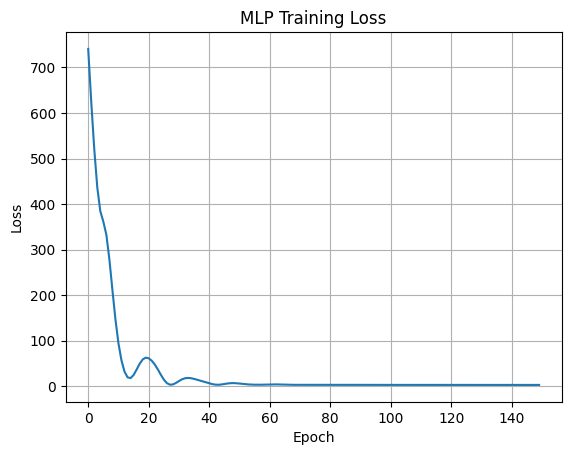

In [ ]:
# Solution for Exercise 3: Multi-Layer Perceptron
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

class MLPNet(nn.Module):
    def __init__(self):
        super(MLPNet, self).__init__()
        # Define a hidden layer (1 input -> 8 outputs)
        self.hidden = nn.Linear(1, 8)

        # Define a ReLU activation
        self.relu = nn.ReLU()

        # Define an output layer (8 inputs -> 1 output)
        self.output = nn.Linear(8, 1)

    def forward(self, x):
        # Pass x through the hidden layer, then ReLU, then output layer
        x = self.hidden(x)
        x = self.relu(x)
        x = self.output(x)
        return x

# Initialize the new model and optimizer
mlp_model = MLPNet()
mlp_optimizer = optim.Adam(mlp_model.parameters(), lr=0.1)
mlp_criterion = nn.MSELoss()

epochs = 150
losses = []

# Training loop
for epoch in range(epochs):
    predictions = mlp_model(X)
    loss = mlp_criterion(predictions, Y)
    mlp_optimizer.zero_grad()
    loss.backward()
    mlp_optimizer.step()
    losses.append(loss.item())

plt.plot(losses)
plt.title("MLP Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

In [ ]:
# ---------------------------------------------------------
# Solution for Exercise 4: Manual Gradient Descent Update
# ---------------------------------------------------------
import torch
import torch.nn as nn

print("\n--- Exercise 4 ---")
layer = nn.Linear(1, 1)
print(f"Original weight: {layer.weight.item():.4f}, bias: {layer.bias.item():.4f}")

# Forward pass
x_dummy = torch.tensor([[2.0]])
y_target = torch.tensor([[5.0]])
y_pred = layer(x_dummy)

# Loss and backward pass
loss_ex4 = (y_pred - y_target)**2
loss_ex4.backward()

# Manual update without tracking gradients
with torch.no_grad():
    layer.weight -= 0.1 * layer.weight.grad
    layer.bias -= 0.1 * layer.bias.grad

print(f"Updated weight: {layer.weight.item():.4f}, bias: {layer.bias.item():.4f}")


--- Exercise 4 ---
Original weight: -0.7671, bias: 0.7192
Updated weight: 1.5589, bias: 1.8822


In [ ]:
# ---------------------------------------------------------
# Solution for Exercise 5: Disabling Autograd
# ---------------------------------------------------------
print("\n--- Exercise 5 ---")
x_test = torch.tensor([[10.0]])

# 1. Normal forward pass (tracks gradients)
out_train = mlp_model(x_test)
print(f"Output requires_grad (Normal): {out_train.requires_grad}")

# 2 & 3. Forward pass with torch.no_grad()
with torch.no_grad():
    out_eval = mlp_model(x_test)
print(f"Output requires_grad (with no_grad): {out_eval.requires_grad}")


--- Exercise 5 ---
Output requires_grad (Normal): True
Output requires_grad (with no_grad): False
